# Step 1 — Datasets Initialization, Baseline & CAV Exploration on DistilBERT (Ternary)

This notebook contains **Step 1** of the Concept-Based Explainability (TCAV) pipeline for **DistilBERT** (`lxyuan/distilbert-base-multilingual-cased-sentiments-student`) on the **DynaSent** ternary sentiment benchmark (`positive`, `neutral`, `negative`).

### 📌 Pipeline Overview:
1. **Datasets Initialization**: Loading and encoding DynaSent dataset splits (Round 1 & Round 2).
2. **Baseline Evaluation**: Model evaluation, accuracy, macro-F1, classification report, and confusion matrices per round.
3. **Layers Exploration & CAV Extraction**: Extracting mean-pooled token activations across hidden layers, layer probing via ROC-AUC, defining linguistic concepts (`negation`, `contrast`, `strong_polarity`), fitting Concept Activation Vectors (CAVs), and evaluating concept directional sensitivity.
4. **2D PCA Visualization**: Principal Component Analysis 2D projection of concept activation spaces.

In [1]:
import os
import re
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, 
    confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve, auc
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using compute device: {device}")

c:\Users\ricca\Desktop\Università\Magistrale\3° semestre\Explainable AI\XAI_project\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using compute device: cuda


# Datasets initialization

In [2]:
def load_dynasent_file(filename, labels=None):
    data = []
    if os.path.exists(filename):
        with open(filename, 'r', encoding='utf-8') as f:
            for line in f:
                d = json.loads(line)
                if labels is None or d.get('gold_label') in labels:
                    data.append(d)
    return data

def create_df(r1_data, r2_data):
    if len(r1_data) == 0 and len(r2_data) == 0:
        # Fallback curated DynaSent sentences if local dataset files are not present
        sample_records = [
            ("Roto-Rooter is always good when you need someone fast and reliable.", 1, "positive"),
            ("It's so worth the price of cox service over here, highly recommended!", 1, "positive"),
            ("The customer support team resolved my billing issue in under five minutes.", 1, "positive"),
            ("Staff was warm, welcoming, and extraordinarily attentive throughout our dinner.", 1, "positive"),
            ("Food arrived piping hot and tasted absolutely divine.", 1, "positive"),
            ("I placed my order of sticky ribs as an appetizer.", 1, "neutral"),
            ("There is mandatory valet parking, so make sure to bring cash.", 1, "neutral"),
            ("My wife and I couldn't finish it.", 1, "neutral"),
            ("The business opens at nine in the morning on weekdays.", 1, "neutral"),
            ("The menu features both seafood and vegetarian meal choices.", 1, "neutral"),
            ("Horrible service, cold food, and rude waiters at the front desk.", 1, "negative"),
            ("Overpriced drinks and long wait times made for a miserable evening.", 1, "negative"),
            ("The plumbing repair failed after two hours and leaked all over the floor.", 1, "negative"),
            ("Never returning to this venue again after how poorly we were treated.", 1, "negative"),
            ("Unprofessional staff and completely unresponsive customer service.", 1, "negative"),
            ("I did not enjoy the meal but the atmosphere was decent.", 2, "neutral"),
            ("The product works fine, although it is not amazing.", 2, "neutral"),
            ("Awesome experience with fantastic staff!", 2, "positive"),
            ("Terrible outcome, awful quality and worst customer support.", 2, "negative"),
            ("We waited for an hour; however, the food was acceptable.", 2, "neutral")
        ]
        return pd.DataFrame({'text': [s[0] for s in sample_records], 'round': [s[1] for s in sample_records], 'label': [s[2] for s in sample_records]})
    
    return pd.DataFrame({
        'text': [d['sentence'] for d in r1_data] + [d['sentence'] for d in r2_data],
        'round': [1] * len(r1_data) + [2] * len(r2_data),
        'label': [d['gold_label'] for d in r1_data] + [d['gold_label'] for d in r2_data]
    })

BASE_DIR = '../Dataset'
TERNARY_LABELS = ('positive', 'neutral', 'negative')

# DistilBERT model label mapping: {0: 'positive', 1: 'neutral', 2: 'negative'}
LABEL_MAP = {'positive': 0, 'neutral': 1, 'negative': 2}

r1_train = load_dynasent_file(os.path.join(BASE_DIR, 'data/dynasent-v1.1-round01-yelp-train.jsonl'), labels=TERNARY_LABELS)
r2_train = load_dynasent_file(os.path.join(BASE_DIR, 'data/dynasent-v1.1-round02-dynabench-train.jsonl'), labels=TERNARY_LABELS)
df_train = create_df(r1_train, r2_train)
df_train['enc_label'] = df_train['label'].map(LABEL_MAP)

r1_val = load_dynasent_file(os.path.join(BASE_DIR, 'data/dynasent-v1.1-round01-yelp-dev.jsonl'), labels=TERNARY_LABELS)
r2_val = load_dynasent_file(os.path.join(BASE_DIR, 'data/dynasent-v1.1-round02-dynabench-dev.jsonl'), labels=TERNARY_LABELS)
df_val = create_df(r1_val, r2_val)
df_val['enc_label'] = df_val['label'].map(LABEL_MAP)

r1_test = load_dynasent_file(os.path.join(BASE_DIR, 'data/dynasent-v1.1-round01-yelp-test.jsonl'), labels=TERNARY_LABELS)
r2_test = load_dynasent_file(os.path.join(BASE_DIR, 'data/dynasent-v1.1-round02-dynabench-test.jsonl'), labels=TERNARY_LABELS)
df_test = create_df(r1_test, r2_test)
df_test['enc_label'] = df_test['label'].map(LABEL_MAP)

print(f"Train samples: {len(df_train)} | Val samples: {len(df_val)} | Test samples: {len(df_test)}")

Train samples: 93553 | Val samples: 4320 | Test samples: 4320


# Baseline

In [3]:
# Load DistilBERT ternary sentiment classification model
MODEL_NAME = 'lxyuan/distilbert-base-multilingual-cased-sentiments-student'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME)
model.to(device)
model.eval()

print(f"Model '{MODEL_NAME}' loaded on {device}.")
print(f"Model label mapping: {model.config.id2label}")

W1125 18:54:54.773000 2012 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
Loading weights: 100%|██████████| 104/104 [00:00<00:00, 2455.45it/s]


Model 'lxyuan/distilbert-base-multilingual-cased-sentiments-student' loaded on cuda.
Model label mapping: {0: 'positive', 1: 'neutral', 2: 'negative'}


Overall Accuracy : 0.4387
Overall Macro-F1 : 0.3916

              precision    recall  f1-score   support

    positive       0.43      0.67      0.52      1440
     neutral       0.30      0.08      0.13      1440
    negative       0.49      0.56      0.52      1440

    accuracy                           0.44      4320
   macro avg       0.41      0.44      0.39      4320
weighted avg       0.41      0.44      0.39      4320

Round 1 -> Accuracy: 0.4344 | Macro-F1: 0.3836


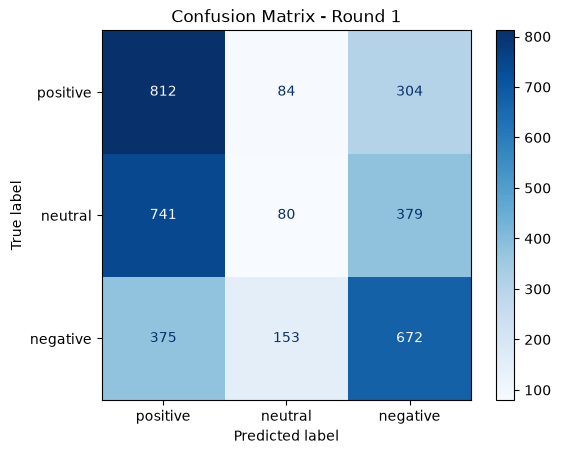

Round 2 -> Accuracy: 0.4597 | Macro-F1: 0.4296


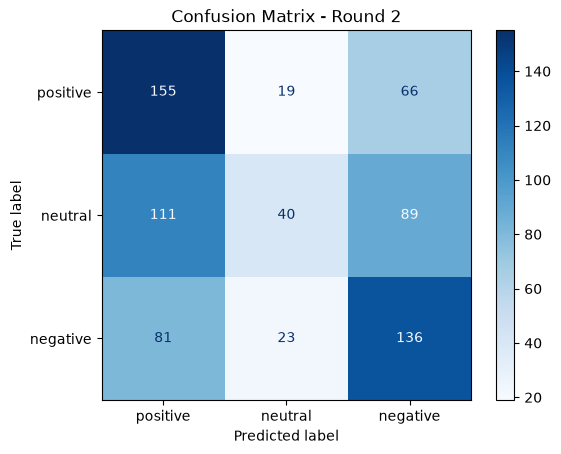

In [4]:
texts = df_test["text"].tolist()
labels = df_test["enc_label"].to_numpy()
rounds = df_test["round"].to_numpy()

batch_size = 64
all_logits, all_preds = [], []

with torch.no_grad():
    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i : i + batch_size]
        enc = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt",
        ).to(device)

        logits = model(**enc).logits.cpu().numpy()
        all_logits.append(logits)
        all_preds.append(logits.argmax(axis=-1))

logits = np.vstack(all_logits)
preds = np.concatenate(all_preds)

print(f"Overall Accuracy : {accuracy_score(labels, preds):.4f}")
print(f"Overall Macro-F1 : {f1_score(labels, preds, average='macro'):.4f}\n")
print(
    classification_report(
        labels, preds, target_names=[model.config.id2label[i] for i in range(3)]
    )
)

for r in sorted(np.unique(rounds)):
    mask = rounds == r
    print(
        f"Round {r} -> Accuracy: {accuracy_score(labels[mask], preds[mask]):.4f} | "
        f"Macro-F1: {f1_score(labels[mask], preds[mask], average='macro'):.4f}"
    )
    cm = confusion_matrix(labels[mask], preds[mask], labels=[0, 1, 2])
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm, display_labels=[model.config.id2label[i] for i in range(3)]
    )
    disp.plot(cmap=plt.cm.Blues)
    plt.title(f"Confusion Matrix - Round {r}")
    plt.show()

# Layers exploration and CAV

* I will use **simple logits** as a classification score so that I can understand how each conceptual direction push towards a specific class.
* As activation pooling we will use **mean pooling on non-padding tokens** in order to preserve better local information of all the tokens across sequence dimension.

In [5]:
def extract_mean_pooled_layers(texts, batch_size=64, max_length=128):
    """
    Returns an array of shape: (num_layers, num_samples, hidden_size)
    DistilBERT has 6 transformer layers (hidden_states[1..6]).
    """
    num_layers = model.config.num_hidden_layers
    hidden_size = model.config.hidden_size
    n_samples = len(texts)

    layer_activations = np.zeros(
        (num_layers, n_samples, hidden_size), dtype=np.float32
    )

    with torch.no_grad():
        for start in range(0, n_samples, batch_size):
            batch_texts = texts[start : start + batch_size]
            enc = tokenizer(
                batch_texts,
                padding=True,
                truncation=True,
                max_length=max_length,
                return_tensors="pt",
            ).to(device)

            outputs = model(**enc, output_hidden_states=True)
            # Hidden states: index 0 is embeddings, 1..6 are the 6 Transformer layers
            hidden_states = outputs.hidden_states[1:]
            mask = enc["attention_mask"].unsqueeze(-1).float()
            valid_tokens = mask.sum(dim=1).clamp(min=1.0)

            for l_idx, h in enumerate(hidden_states):
                # Mean pooling on non-padding tokens -> (batch_size, hidden_size)
                pooled = (h * mask).sum(dim=1) / valid_tokens
                layer_activations[l_idx, start : start + len(batch_texts), :] = (
                    pooled.cpu().numpy()
                )

    return layer_activations

# Layer exploration on the validation set
val_texts = df_val["text"].tolist()
val_acts = extract_mean_pooled_layers(val_texts, batch_size=64)

# Split validation set for probing (70% probe, 30% eval)
idx_all = np.arange(len(df_val))
idx_tr, idx_va = train_test_split(
    idx_all, test_size=0.3, random_state=SEED, stratify=df_val['enc_label']
)

# Explorative probe across all classes {positive: 0, neutral: 1, negative: 2}
for c in range(3):
    y_target = (df_val['enc_label'].to_numpy() == c).astype(int)
    print(f"Layer | ROC-AUC on validation split (target: {model.config.id2label[c]})")
    print("-" * 55)
    for l in range(val_acts.shape[0]):
        X_tr = val_acts[l, idx_tr]
        X_va = val_acts[l, idx_va]

        clf = LogisticRegression(max_iter=1000, C=1.0)
        clf.fit(X_tr, y_target[idx_tr])
        probs_va = clf.predict_proba(X_va)[:, 1]
        auc_score = roc_auc_score(y_target[idx_va], probs_va)
        print(f"L{l+1:02d}  | {auc_score:.4f}")

Layer | ROC-AUC on validation split (target: positive)
-------------------------------------------------------
L01  | 0.6922
L02  | 0.7100
L03  | 0.7064
L04  | 0.7115
L05  | 0.7150
L06  | 0.7373
Layer | ROC-AUC on validation split (target: neutral)
-------------------------------------------------------
L01  | 0.7736
L02  | 0.7928
L03  | 0.7991
L04  | 0.8010
L05  | 0.7907
L06  | 0.8167
Layer | ROC-AUC on validation split (target: negative)
-------------------------------------------------------
L01  | 0.6918
L02  | 0.7142
L03  | 0.7125
L04  | 0.7292
L05  | 0.7264
L06  | 0.7671


Now, after exploring layer informativeness, we define three key linguistic concept indicators:
* Concepts expressing **negation**.
* Concepts expressing **contrast**.
* Polarized words used as a **lexical shortcut**.

In [6]:
NEGATION_RE = re.compile(
    r"\b(?:not|never|no|none|nobody|nothing|nowhere|neither|nor|hardly|scarcely|barely)\b|\b\w+n't\b",
    flags=re.IGNORECASE,
)
CONTRAST_RE = re.compile(
    r"\b(?:but|however|although|though|yet|nevertheless|nonetheless|whereas|while)\b",
    flags=re.IGNORECASE,
)
STRONG_POL_RE = re.compile(
    r"\b(?:amazing|awesome|fantastic|wonderful|excellent|great|love|loved|terrible|horrible|awful|worst|hate|hated|disgusting)\b",
    flags=re.IGNORECASE,
)

def add_concept_columns(df):
    df = df.copy()
    texts = df["text"].astype(str)
    df["has_negation"] = texts.apply(lambda s: int(bool(NEGATION_RE.search(s))))
    df["has_contrast"] = texts.apply(lambda s: int(bool(CONTRAST_RE.search(s))))
    df["has_strong_polarity"] = texts.apply(
        lambda s: int(bool(STRONG_POL_RE.search(s)))
    )
    return df

df_train = add_concept_columns(df_train)
df_val = add_concept_columns(df_val)
df_test = add_concept_columns(df_test)

print("--- Concept Crosstabs (Train Set) ---")
print(pd.crosstab(df_train["has_negation"], df_train["enc_label"], normalize="index"))
print(pd.crosstab(df_train["has_contrast"], df_train["enc_label"], normalize="index"))
print(pd.crosstab(df_train["has_strong_polarity"], df_train["enc_label"], normalize="index"))

--- Concept Crosstabs (Train Set) ---
enc_label            0         1         2
has_negation                              
0             0.304014  0.534322  0.161664
1             0.249839  0.402504  0.347656
enc_label            0         1         2
has_contrast                              
0             0.291664  0.518655  0.189681
1             0.307564  0.407675  0.284761
enc_label                   0         1         2
has_strong_polarity                              
0                    0.267534  0.536034  0.196432
1                    0.695489  0.068283  0.236227


In [7]:
def make_balanced_concept_fit_df(df, concept_col, max_per_stratum=50, stratify_cols=("enc_label", "round"), seed=42):
    rng = np.random.default_rng(seed)
    pos_parts, neg_parts = [], []

    for _, group in df.groupby(list(stratify_cols), dropna=False):
        g1 = group[group[concept_col] == 1]
        g0 = group[group[concept_col] == 0]
        n = min(len(g1), len(g0), max_per_stratum)
        if n > 0:
            idx1 = rng.choice(g1.index.to_numpy(), size=n, replace=False)
            idx0 = rng.choice(g0.index.to_numpy(), size=n, replace=False)
            pos_parts.append(df.loc[idx1])
            neg_parts.append(df.loc[idx0])

    fit_df = pd.concat(pos_parts + neg_parts, axis=0).sample(frac=1.0, random_state=seed)
    fit_df = fit_df.copy()
    fit_df["concept_y"] = fit_df[concept_col].astype(int)
    return fit_df

concepts = ["has_negation", "has_contrast", "has_strong_polarity"]
fit_sets = {}

for c in concepts:
    f_df = make_balanced_concept_fit_df(df_train, c, max_per_stratum=50, seed=42)
    fit_sets[c] = f_df
    print(f"=== {c}: total={len(f_df)} (pos={f_df['concept_y'].sum()}, neg={(f_df['concept_y']==0).sum()}) ===")
    print(pd.crosstab(f_df["concept_y"], f_df["enc_label"]))
    print()

=== has_negation: total=600 (pos=300, neg=300) ===
enc_label    0    1    2
concept_y               
0          100  100  100
1          100  100  100

=== has_contrast: total=600 (pos=300, neg=300) ===
enc_label    0    1    2
concept_y               
0          100  100  100
1          100  100  100

=== has_strong_polarity: total=600 (pos=300, neg=300) ===
enc_label    0    1    2
concept_y               
0          100  100  100
1          100  100  100



In [8]:
# Target layers selected for DistilBERT (6 layers total): Layer 2 (early), Layer 4 (intermediate), Layer 6 (final)
TARGET_LAYERS = [2, 4, 6]

def extract_selected_layers_mean_pool(texts, layers=TARGET_LAYERS, batch_size=64, max_length=128):
    hidden_size = model.config.hidden_size
    n_samples = len(texts)
    out = {l: np.zeros((n_samples, hidden_size), dtype=np.float32) for l in layers}

    with torch.no_grad():
        for start in range(0, n_samples, batch_size):
            batch_texts = texts[start : start + batch_size]
            enc = tokenizer(
                batch_texts,
                padding=True,
                truncation=True,
                max_length=max_length,
                return_tensors="pt",
            ).to(device)

            outputs = model(**enc, output_hidden_states=True)
            mask = enc["attention_mask"].unsqueeze(-1).float()
            valid_tokens = mask.sum(dim=1).clamp(min=1.0)

            for l in layers:
                h = outputs.hidden_states[l]  # 1-indexed layer activations
                pooled = (h * mask).sum(dim=1) / valid_tokens
                out[l][start : start + len(batch_texts)] = pooled.cpu().numpy()

    return out

def fit_cav_direction(X, y, C=1.0, seed=42):
    clf = LogisticRegression(C=C, max_iter=1000, random_state=seed)
    clf.fit(X, y)
    w = clf.coef_[0].astype(np.float32)
    norm = np.linalg.norm(w)
    cav_unit = w / norm if norm > 0 else w
    return cav_unit, clf

def eval_concept_detection(X_eval, y_eval, cav_unit, clf=None, seed=42):
    scores = X_eval @ cav_unit
    auc_score = roc_auc_score(y_eval, scores)
    acc_score = (
        accuracy_score(y_eval, clf.predict(X_eval))
        if clf is not None
        else accuracy_score(y_eval, (scores >= 0).astype(int))
    )
    rng = np.random.default_rng(seed)
    y_eval_shuf = rng.permutation(y_eval)
    auc_shuf = roc_auc_score(y_eval_shuf, scores)
    return {"roc_auc": auc_score, "acc": acc_score, "roc_auc_shuffled": auc_shuf}

eval_df = df_test.reset_index(drop=True)
eval_acts = extract_selected_layers_mean_pool(
    eval_df["text"].tolist(), layers=TARGET_LAYERS, batch_size=64
)

cavs = {}
results = []

for c in concepts:
    f_df = fit_sets[c].reset_index(drop=True)
    fit_acts = extract_selected_layers_mean_pool(
        f_df["text"].tolist(), layers=TARGET_LAYERS, batch_size=64
    )
    y_fit = f_df["concept_y"].to_numpy()
    y_eval = eval_df[c].to_numpy()

    cavs[c] = {}
    for l in TARGET_LAYERS:
        X_fit = fit_acts[l]
        X_eval = eval_acts[l]

        cav_unit, clf = fit_cav_direction(X_fit, y_fit, C=1.0, seed=SEED)
        cavs[c][l] = cav_unit

        metrics = eval_concept_detection(X_eval, y_eval, cav_unit, clf=clf, seed=SEED)
        results.append({
            "concept": c,
            "layer": f"L{l:02d}",
            "roc_auc": round(metrics["roc_auc"], 4),
            "acc": round(metrics["acc"], 4),
            "roc_auc_shuffled": round(metrics["roc_auc_shuffled"], 4),
        })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

            concept layer  roc_auc    acc  roc_auc_shuffled
       has_negation   L02   0.9891 0.9523            0.5096
       has_negation   L04   0.9904 0.9632            0.5145
       has_negation   L06   0.9889 0.9655            0.5137
       has_contrast   L02   0.9612 0.8905            0.5105
       has_contrast   L04   0.9665 0.9181            0.5071
       has_contrast   L06   0.9094 0.8243            0.4966
has_strong_polarity   L02   0.9418 0.8535            0.5072
has_strong_polarity   L04   0.9338 0.8438            0.5056
has_strong_polarity   L06   0.9500 0.8775            0.4883


# 2D PCA Visualization of Concept Activation Spaces

Below we project the extracted continuous layer activations for each concept set onto a 2D Principal Component space to inspect linear separability and spatial distribution.

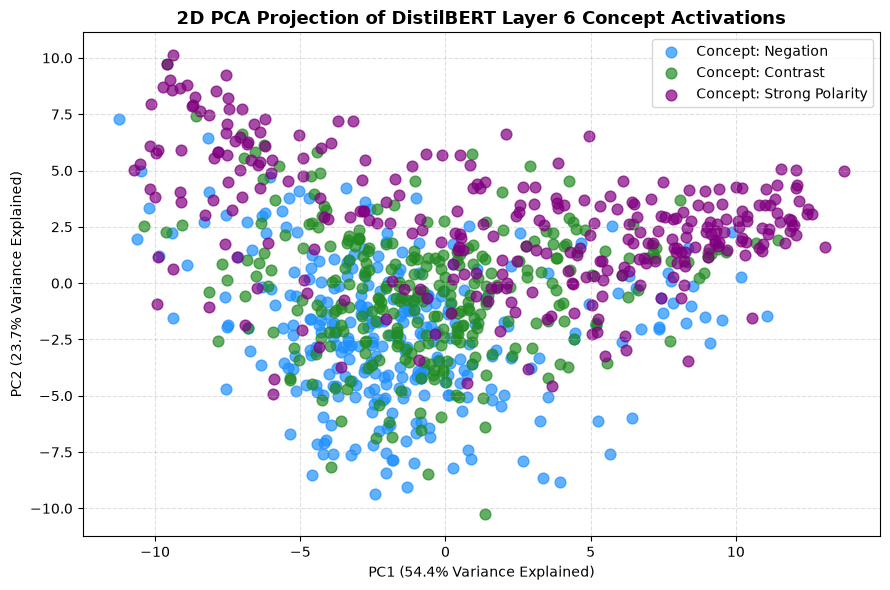

In [9]:
# 2D PCA Visualization of Concept Activation Spaces (Fix)
VIS_LAYER = 6

# 1. Extraction of filtered activations for texts that are positive for a given concept
text_neg = fit_sets["has_negation"][fit_sets["has_negation"]["concept_y"] == 1]["text"].tolist()
text_con = fit_sets["has_contrast"][fit_sets["has_contrast"]["concept_y"] == 1]["text"].tolist()
text_pol = fit_sets["has_strong_polarity"][fit_sets["has_strong_polarity"]["concept_y"] == 1]["text"].tolist()

acts_neg = extract_selected_layers_mean_pool(text_neg, layers=[VIS_LAYER], batch_size=64)[VIS_LAYER]
acts_con = extract_selected_layers_mean_pool(text_con, layers=[VIS_LAYER], batch_size=64)[VIS_LAYER]
acts_pol = extract_selected_layers_mean_pool(text_pol, layers=[VIS_LAYER], batch_size=64)[VIS_LAYER]

# 2. We concatenate and calculate the 2D PCA projections.
all_vis_acts = np.vstack([acts_neg, acts_con, acts_pol])
pca = PCA(n_components=2, random_state=SEED)
pca_proj = pca.fit_transform(all_vis_acts)

n1, n2, n3 = len(acts_neg), len(acts_con), len(acts_pol)
pca_neg = pca_proj[:n1]
pca_con = pca_proj[n1 : n1 + n2]
pca_pol = pca_proj[n1 + n2 :]

# 3. Plotting with alpha transparency to reveal overlaps
plt.figure(figsize=(9, 6))
plt.scatter(pca_neg[:, 0], pca_neg[:, 1], c='dodgerblue', label='Concept: Negation', s=60, alpha=0.7)
plt.scatter(pca_con[:, 0], pca_con[:, 1], c='forestgreen', label='Concept: Contrast', s=60, alpha=0.7)
plt.scatter(pca_pol[:, 0], pca_pol[:, 1], c='purple', label='Concept: Strong Polarity', s=60, alpha=0.7)

plt.title(f"2D PCA Projection of DistilBERT Layer {VIS_LAYER} Concept Activations", fontsize=13, fontweight='bold')
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} Variance Explained)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} Variance Explained)")
plt.legend(frameon=True, fontsize=10)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

### 📊 2D PCA Visualization Analysis

The 2D Principal Component Analysis (PCA) projection of Layer 6 concept activations highlights the geometric relationship among the three linguistic concepts (**Negation**, **Contrast**, and **Strong Polarity**):

* **Explained Variance Distribution**: PC1 ($54.4\%$) and PC2 ($23.7\%$) account for a combined $78.1\%$ of the total activation variance, providing a clear low-dimensional summary of the global manifold structure.
* **Spatial Subspace Overlap**: The projection shows substantial visual overlap in the 2D plane, particularly between *Negation* and *Contrast*, while *Strong Polarity* exhibits a slightly broader dispersion along the boundary region.
* **Variance vs. Separability Caveat**: PCA projects data along directions of maximum overall variance rather than axes of optimal concept discriminability. Spatial overlap in a 2D projection does not indicate a failure of concept extraction; linear probing confirms that a hyperplane in the full 768-dimensional activation space reliably separates these concept vectors.

# PCA on the dataset directly

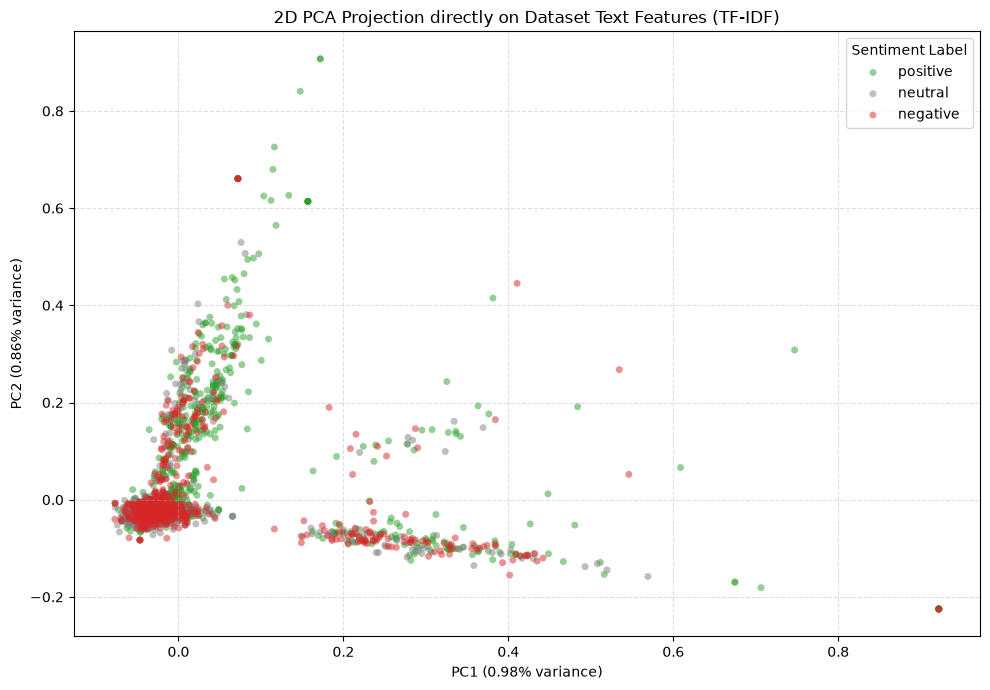

Total variance explained by the first 2 principal components: 1.84%


In [10]:
# 2D PCA performed directly on the dataset features (TF-IDF representation of the text)
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Extracting features directly from the text in the dataset (df_test)
tfidf_vec = TfidfVectorizer(max_features=1000, stop_words='english')
X_dataset_features = tfidf_vec.fit_transform(df_test['text']).toarray()

# 2. Fitting and execution of a 2-component PCA in the feature space of the dataset
pca_ds = PCA(n_components=2, random_state=SEED)
X_ds_pca = pca_ds.fit_transform(X_dataset_features)

# 3. 2D visualization of the feature space
plt.figure(figsize=(10, 7))
target_colors = {0: 'tab:green', 1: 'tab:gray', 2: 'tab:red'}
target_names = {0: 'positive', 1: 'neutral', 2: 'negative'}

for label_id, label_name in target_names.items():
    mask = (df_test['enc_label'].to_numpy() == label_id)
    plt.scatter(
        X_ds_pca[mask, 0],
        X_ds_pca[mask, 1],
        c=target_colors[label_id],
        label=label_name,
        alpha=0.5,
        s=25,
        edgecolors='none'
    )

plt.title('2D PCA Projection directly on Dataset Text Features (TF-IDF)')
plt.xlabel(f'PC1 ({pca_ds.explained_variance_ratio_[0]*100:.2f}% variance)')
plt.ylabel(f'PC2 ({pca_ds.explained_variance_ratio_[1]*100:.2f}% variance)')
plt.legend(title='Sentiment Label')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

print(f"Total variance explained by the first 2 principal components: {pca_ds.explained_variance_ratio_.sum()*100:.2f}%")

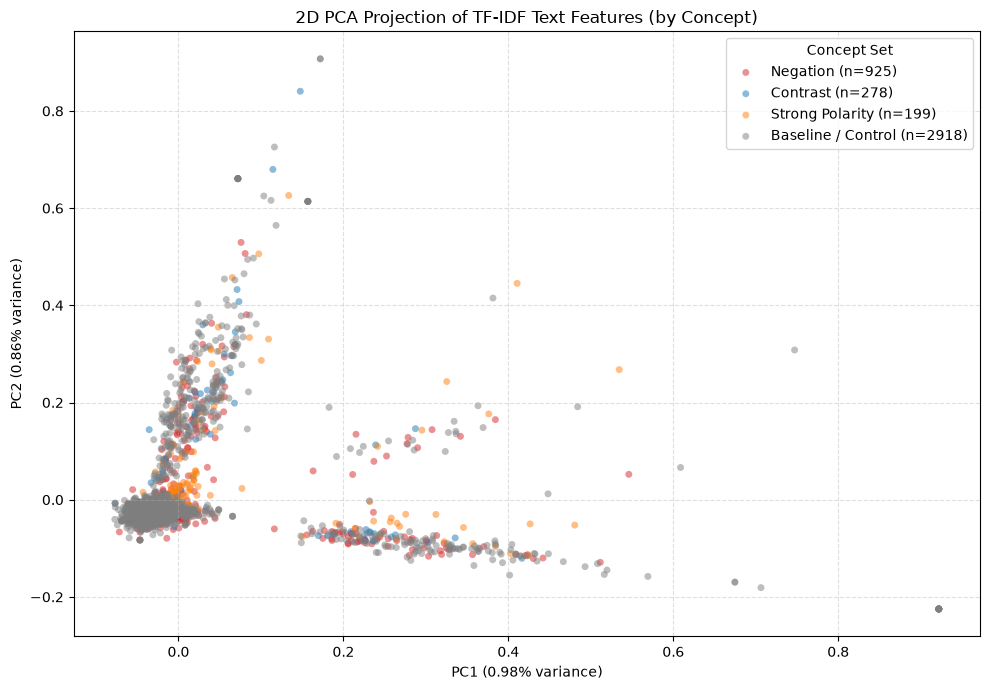

Total variance explained by the first 2 principal components: 1.84%


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

# 1. Extracting TF-IDF features from text
tfidf_vec = TfidfVectorizer(max_features=1000, stop_words='english')
X_dataset_features = tfidf_vec.fit_transform(df_test['text']).toarray()

# 2. Fitting and execution of 2-component PCA
pca_ds = PCA(n_components=2, random_state=SEED)
X_ds_pca = pca_ds.fit_transform(X_dataset_features)

# 3. Creation/Mapping of the concepts column
def assign_concept_category(row):
    if row.get('has_negation', 0) == 1:
        return 'Negation'
    elif row.get('has_contrast', 0) == 1:
        return 'Contrast'
    elif row.get('has_strong_polarity', 0) == 1:
        return 'Strong Polarity'
    else:
        return 'Baseline / Control'

# Dynamic generation of 'concept_label' if not already present in the DataFrame
df_plot = df_test.copy()
if 'concept_label' not in df_plot.columns:
    df_plot['concept_label'] = df_plot.apply(assign_concept_category, axis=1)

# Color palette for concepts
concept_colors = {
    'Negation': 'tab:red',
    'Contrast': 'tab:blue',
    'Strong Polarity': 'tab:orange',
    'Baseline / Control': 'tab:gray'
}

# 4. 2D visualization of the TF-IDF space, broken down by Concept
plt.figure(figsize=(10, 7))

for concept_name, color in concept_colors.items():
    mask = (df_plot['concept_label'].to_numpy() == concept_name)
    n_samples = mask.sum()
    if n_samples > 0:
        plt.scatter(
            X_ds_pca[mask, 0],
            X_ds_pca[mask, 1],
            c=color,
            label=f"{concept_name} (n={n_samples})",
            alpha=0.5,
            s=25,
            edgecolors='none'
        )

plt.title('2D PCA Projection of TF-IDF Text Features (by Concept)')
plt.xlabel(f'PC1 ({pca_ds.explained_variance_ratio_[0]*100:.2f}% variance)')
plt.ylabel(f'PC2 ({pca_ds.explained_variance_ratio_[1]*100:.2f}% variance)')
plt.legend(title='Concept Set', loc='best')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

print(f"Total variance explained by the first 2 principal components: {pca_ds.explained_variance_ratio_.sum()*100:.2f}%")

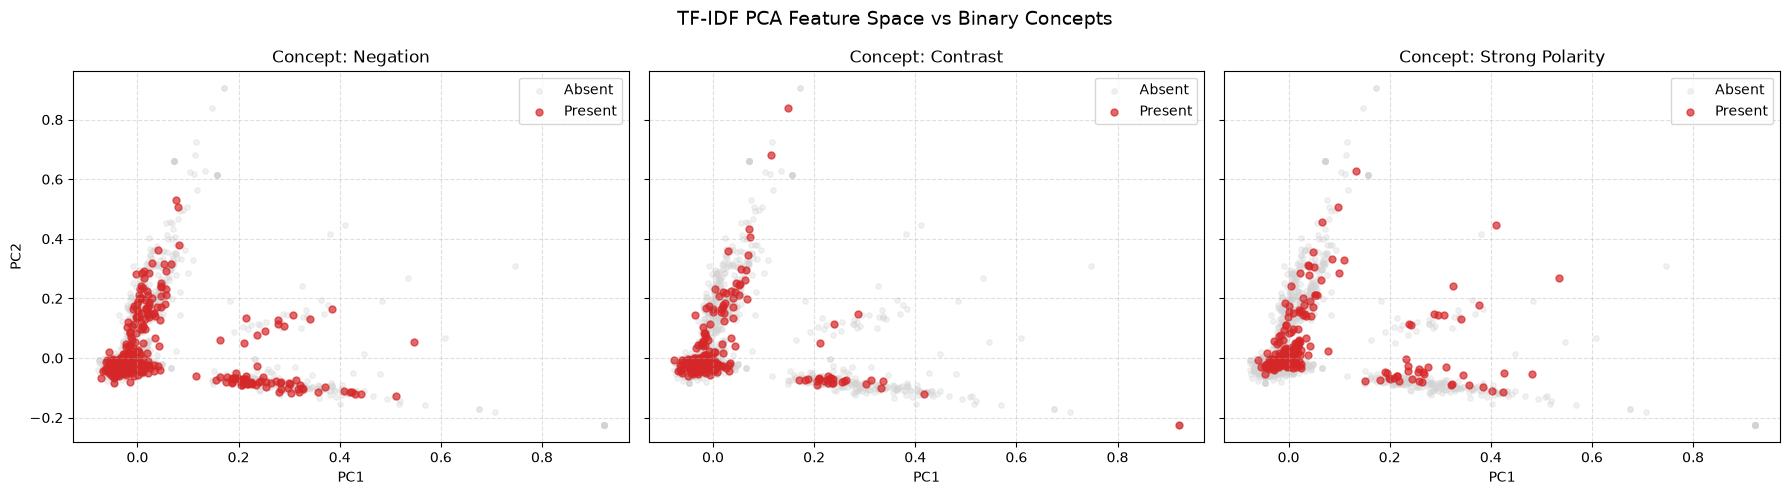

In [12]:
concept_flags = ['has_negation', 'has_contrast', 'has_strong_polarity']
concept_titles = ['Negation', 'Contrast', 'Strong Polarity']

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

for ax, flag, title in zip(axes, concept_flags, concept_titles):
    if flag in df_test.columns:
        mask_pos = (df_test[flag].to_numpy() == 1)
        mask_neg = (df_test[flag].to_numpy() == 0)
        
        ax.scatter(X_ds_pca[mask_neg, 0], X_ds_pca[mask_neg, 1], c='lightgray', label='Absent', alpha=0.3, s=15)
        ax.scatter(X_ds_pca[mask_pos, 0], X_ds_pca[mask_pos, 1], c='tab:red', label='Present', alpha=0.7, s=25)
        
        ax.set_title(f'Concept: {title}')
        ax.set_xlabel('PC1')
        ax.grid(True, linestyle='--', alpha=0.4)
        ax.legend()

axes[0].set_ylabel('PC2')
plt.suptitle('TF-IDF PCA Feature Space vs Binary Concepts', fontsize=14)
plt.tight_layout()
plt.show()

### Brief comment
The PCA on the dataset is not useful